# Descomposicion de serie de tiempo en componentes de Tendencia, estacional y residual

In [1]:
# ================================================================
# 1. IMPORTAR LIBRERÍAS
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error


# ================================================================
# 2. CARGAR ARCHIVO EXCEL DESDE LA COMPUTADORA
# ================================================================

# Leer archivo Excel
df = pd.read_csv("../data/datos_clima.csv")

print("\nDimensiones del dataset:", df.shape)

print("\nColumnas disponibles:")
print(df.columns.tolist())

print("\nPrimeras observaciones:")
display(df.head())


Dimensiones del dataset: (4320, 5)

Columnas disponibles:
['Fecha', 'Hora', 'T', 'H', 'datetime']

Primeras observaciones:


,Fecha,Hora,T,H,datetime
0,03/11/2026,14:06:01,23.6,49,2026-03-11 14:06:01
1,03/11/2026,14:07:00,23.9,50,2026-03-11 14:07:00
2,03/11/2026,14:08:00,24.2,50,2026-03-11 14:08:00
3,03/11/2026,14:09:00,24.5,50,2026-03-11 14:09:00
4,03/11/2026,14:10:00,24.9,50,2026-03-11 14:10:00


In [2]:
# ================================================================
# 3. PREPARAR TEMPERATURA Y HUMEDAD RELATIVA
# ================================================================

df["datetime"] = pd.to_datetime(df["datetime"], dayfirst=True)

datos = df[
    ["datetime", "T", "H"]
].copy()

datos = datos.sort_values("datetime")
datos = datos.dropna()
datos = datos.set_index("datetime")

print("Número de observaciones:", len(datos))

display(datos.head())

Número de observaciones: 4320


,T,H
datetime,,
2026-11-03 14:06:01,23.6,49
2026-11-03 14:07:00,23.9,50
2026-11-03 14:08:00,24.2,50
2026-11-03 14:09:00,24.5,50
2026-11-03 14:10:00,24.9,50



Dimensiones: (4320, 5)

Columnas:
['Fecha', 'Hora', 'T', 'H', 'datetime']

Número de observaciones: 4320

Periodo de observación:
2026-11-03 14:06:01 a 2026-11-06 14:05:00


,T,H
datetime,,
2026-11-03 14:06:01,23.6,49
2026-11-03 14:07:00,23.9,50
2026-11-03 14:08:00,24.2,50
2026-11-03 14:09:00,24.5,50
2026-11-03 14:10:00,24.9,50



INTERVALO DE MUESTREO
Intervalo mediano: 1.00 minutos
Muestras aproximadas por hora: 60.00
Muestras aproximadas por día: 1440.00

Periodo estacional diario candidato: m = 1440


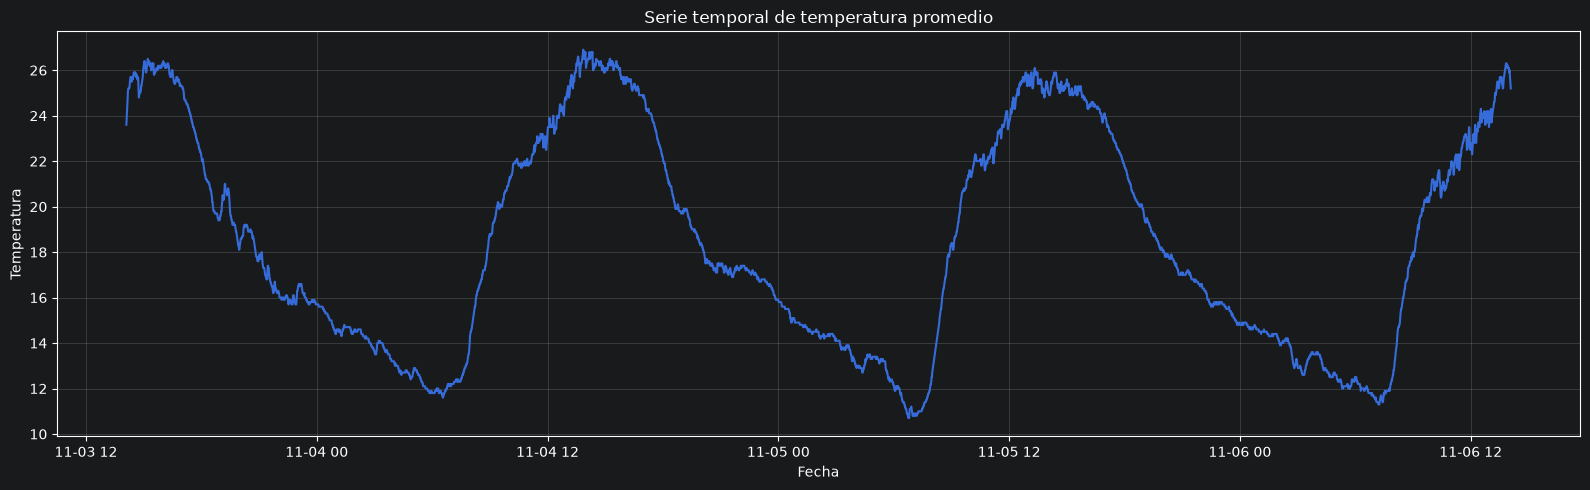

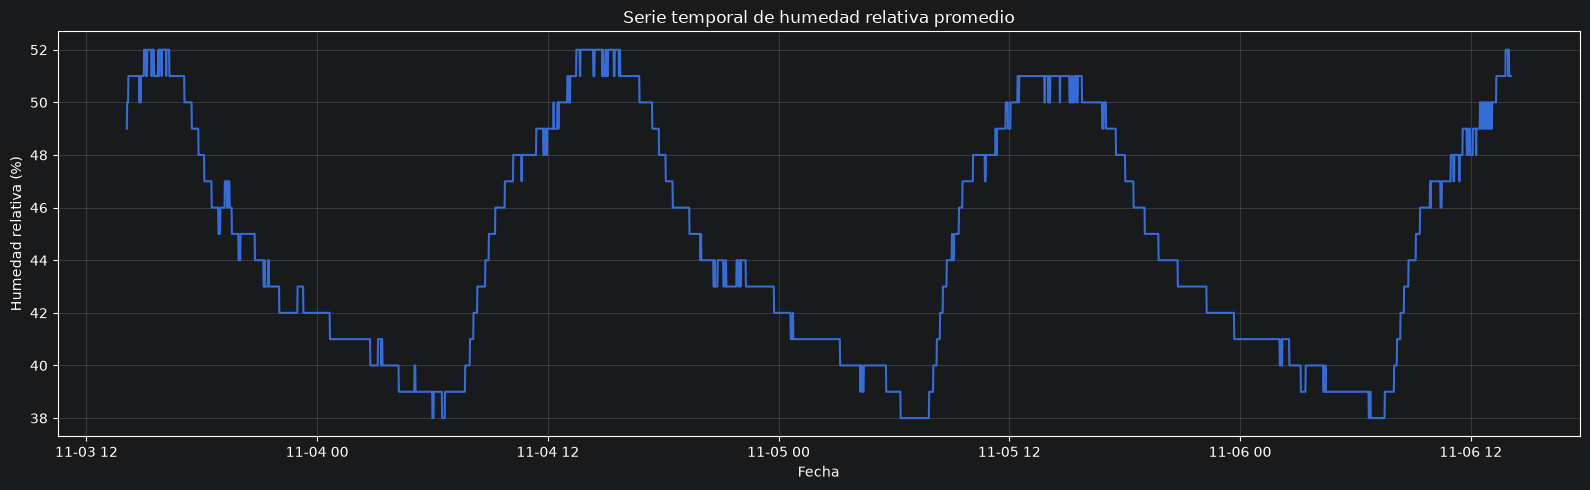

<Figure size 1600x600 with 0 Axes>

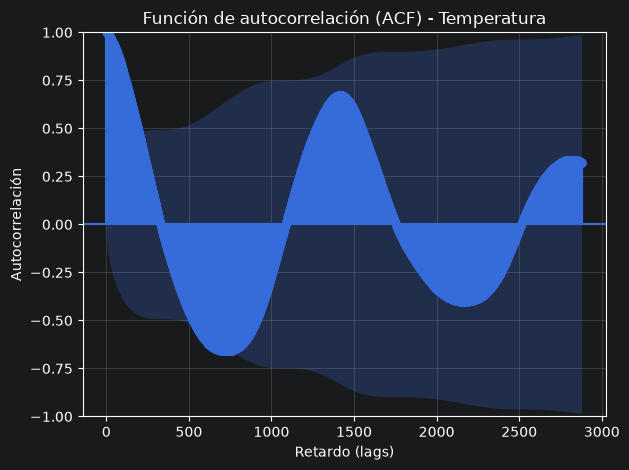

<Figure size 1600x600 with 0 Axes>

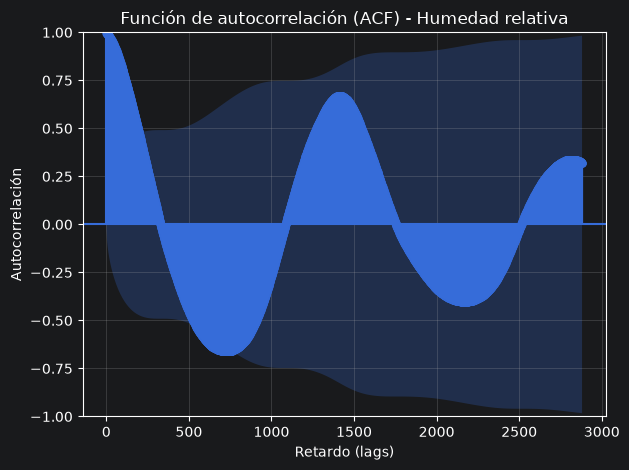


AUTOCORRELACIÓN EN CICLOS DIARIOS

Variable: T
1 día(s) (lag=1440): 0.9884
2 día(s) (lag=2880): 0.9937
3 día(s) (lag=4320): nan
4 día(s) (lag=5760): nan
5 día(s) (lag=7200): nan
6 día(s) (lag=8640): nan
7 día(s) (lag=10080): nan

Variable: H
1 día(s) (lag=1440): 0.9845
2 día(s) (lag=2880): 0.9886
3 día(s) (lag=4320): nan
4 día(s) (lag=5760): nan
5 día(s) (lag=7200): nan
6 día(s) (lag=8640): nan
7 día(s) (lag=10080): nan

PERIODOS DOMINANTES: Temperatura
Periodo =   24.000 horas | Potencia = 1.4287e+03
Periodo =   12.000 horas | Potencia = 1.3448e+02
Periodo =    6.000 horas | Potencia = 1.5916e+01
Periodo =    8.000 horas | Potencia = 9.6872e+00
Periodo =    4.000 horas | Potencia = 5.5586e+00
Periodo =    3.429 horas | Potencia = 3.5614e+00
Periodo =    4.800 horas | Potencia = 3.4979e+00
Periodo =    3.130 horas | Potencia = 4.3379e-01
Periodo =    2.483 horas | Potencia = 3.2514e-01
Periodo =    2.323 horas | Potencia = 2.3094e-01


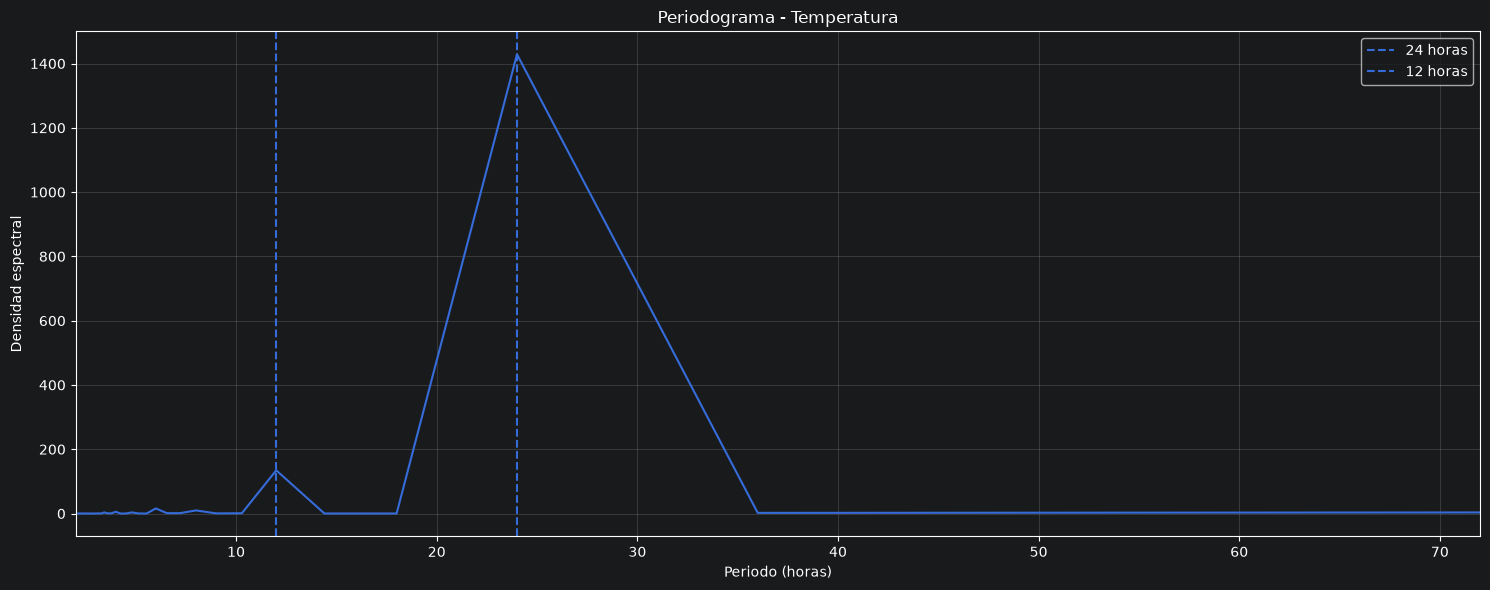


PERIODOS DOMINANTES: Humedad relativa
Periodo =   24.000 horas | Potencia = 1.1845e+03
Periodo =   12.000 horas | Potencia = 1.0964e+02
Periodo =    6.000 horas | Potencia = 1.2911e+01
Periodo =    8.000 horas | Potencia = 8.3848e+00
Periodo =    4.000 horas | Potencia = 4.3576e+00
Periodo =    3.429 horas | Potencia = 3.4018e+00
Periodo =    4.800 horas | Potencia = 2.5757e+00
Periodo =    2.483 horas | Potencia = 2.8056e-01
Periodo =    2.182 horas | Potencia = 2.3438e-01
Periodo =    2.323 horas | Potencia = 2.2140e-01


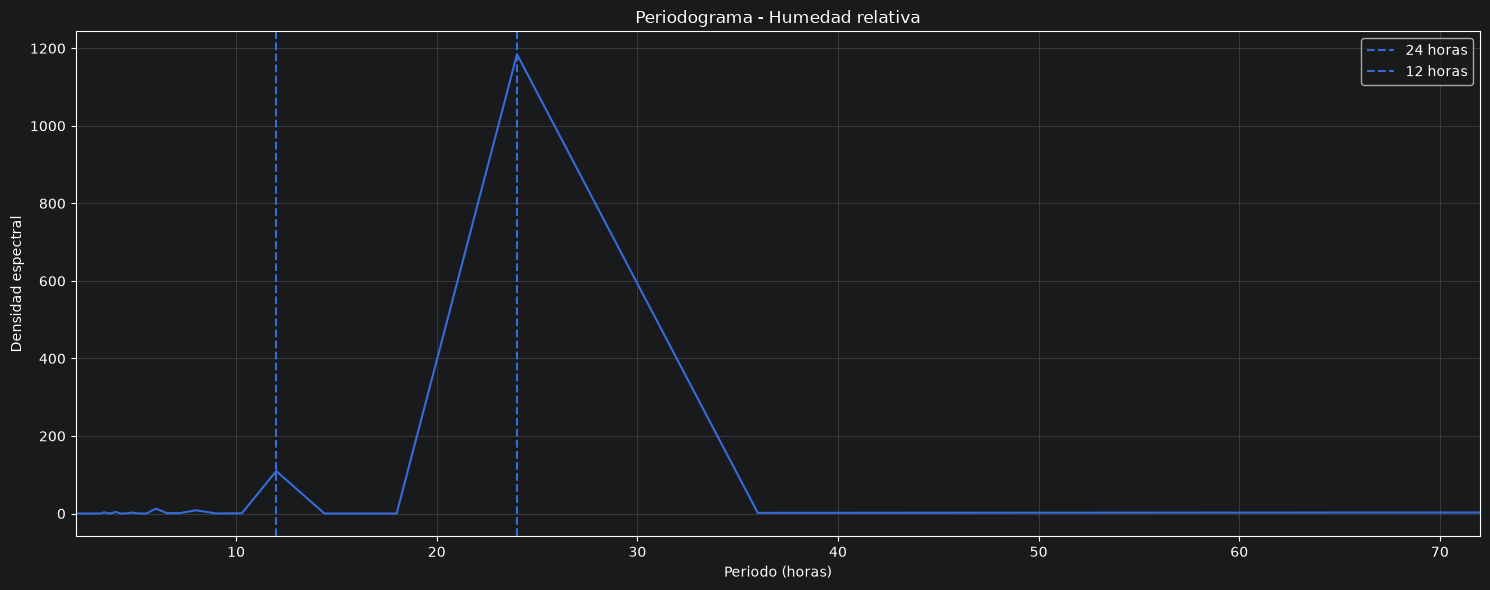

In [3]:
# ================================================================
# ANÁLISIS DE PERIODICIDAD
# Temperatura y Humedad Relativa
# ================================================================

# ------------------------------------------------
# 1. LIBRERÍAS
# ------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf
from scipy.signal import periodogram, find_peaks


# ================================================================
# 2. CARGAR ARCHIVO EXCEL
# ================================================================

df = pd.read_csv("../data/datos_clima.csv")

print("\nDimensiones:", df.shape)
print("\nColumnas:")
print(df.columns.tolist())


# ================================================================
# 3. PREPARAR DATOS
# ================================================================

df["datetime"] = pd.to_datetime(
    df["datetime"],
    dayfirst=True,
    errors="coerce"
)

datos = df[
    ["datetime", "T", "H"]
].copy()

datos = datos.dropna()

datos = datos.sort_values("datetime")

# Eliminar fechas duplicadas, si existen
datos = datos.drop_duplicates(
    subset="datetime"
)

datos = datos.set_index("datetime")


print("\nNúmero de observaciones:", len(datos))

print("\nPeriodo de observación:")
print(datos.index.min(), "a", datos.index.max())

display(datos.head())


# ================================================================
# 4. DETERMINAR INTERVALO DE MUESTREO
# ================================================================

diferencias = datos.index.to_series().diff().dropna()

delta_mediana = diferencias.median()

delta_minutos = (
    delta_mediana.total_seconds() / 60
)

print("\n==========================================")
print("INTERVALO DE MUESTREO")
print("==========================================")

print(
    f"Intervalo mediano: "
    f"{delta_minutos:.2f} minutos"
)

muestras_hora = 60 / delta_minutos
muestras_dia = 24 * muestras_hora

print(
    f"Muestras aproximadas por hora: "
    f"{muestras_hora:.2f}"
)

print(
    f"Muestras aproximadas por día: "
    f"{muestras_dia:.2f}"
)

m_diario = int(round(muestras_dia))

print(
    f"\nPeriodo estacional diario candidato: "
    f"m = {m_diario}"
)


# ================================================================
# 5. VISUALIZAR SERIES
# ================================================================

plt.figure(figsize=(16,5))

plt.plot(
    datos.index,
    datos["T"]
)

plt.title(
    "Serie temporal de temperatura promedio"
)

plt.xlabel("Fecha")
plt.ylabel("Temperatura")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


plt.figure(figsize=(16,5))

plt.plot(
    datos.index,
    datos["H"]
)

plt.title(
    "Serie temporal de humedad relativa promedio"
)

plt.xlabel("Fecha")
plt.ylabel("Humedad relativa (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ================================================================
# 6. AUTOCORRELACIÓN (ACF)
# ================================================================
#
# Se analizan hasta 7 días.
# Si el intervalo es de 5 minutos:
#
# 1 día = 288 retardos
# 2 días = 576
# 3 días = 864
# ...
#
# ================================================================

max_lag = 2 * m_diario


# ------------------------------------------------
# ACF TEMPERATURA
# ------------------------------------------------

plt.figure(figsize=(16,6))

plot_acf(
    datos["T"],
    lags=max_lag,
    zero=False
)

plt.title(
    "Función de autocorrelación (ACF) - Temperatura"
)

plt.xlabel("Retardo (lags)")
plt.ylabel("Autocorrelación")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# ACF HUMEDAD
# ------------------------------------------------

plt.figure(figsize=(16,6))

plot_acf(
    datos["H"],
    lags=max_lag,
    zero=False
)

plt.title(
    "Función de autocorrelación (ACF) - Humedad relativa"
)

plt.xlabel("Retardo (lags)")
plt.ylabel("Autocorrelación")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ================================================================
# 7. AUTOCORRELACIÓN EN RETARDOS DE 24 HORAS
# ================================================================

print("\n==========================================")
print("AUTOCORRELACIÓN EN CICLOS DIARIOS")
print("==========================================")

for variable in ["T", "H"]:

    print("\nVariable:", variable)

    for dia in range(1, 8):

        lag = dia * m_diario

        correlacion = datos[variable].autocorr(
            lag=lag
        )

        print(
            f"{dia} día(s) "
            f"(lag={lag}): "
            f"{correlacion:.4f}"
        )


# ================================================================
# 8. PERIODOGRAMA
# ================================================================
#
# La frecuencia de muestreo se expresa en muestras/hora.
#
# El periodo obtenido estará expresado en horas.
# ================================================================

fs = muestras_hora


def analizar_periodograma(serie, nombre):

    # Eliminar media
    x = serie.values
    x = x - np.mean(x)

    # Calcular periodograma
    frecuencias, potencia = periodogram(
        x,
        fs=fs,
        detrend="linear"
    )

    # Eliminar frecuencia cero
    mascara = frecuencias > 0

    frecuencias = frecuencias[mascara]
    potencia = potencia[mascara]

    # Convertir frecuencia a periodo
    periodos_horas = 1 / frecuencias

    # ------------------------------------------------
    # Buscar periodos entre 2 horas y 7 días
    # ------------------------------------------------

    mascara_periodo = (
        (periodos_horas >= 2) &
        (periodos_horas <= 168)
    )

    p = periodos_horas[mascara_periodo]
    power = potencia[mascara_periodo]

    # ------------------------------------------------
    # Encontrar picos
    # ------------------------------------------------

    peaks, _ = find_peaks(power)

    if len(peaks) > 0:

        indices = peaks[
            np.argsort(power[peaks])[-10:]
        ]

        indices = indices[
            np.argsort(power[indices])[::-1]
        ]

        print("\n==========================================")
        print("PERIODOS DOMINANTES:", nombre)
        print("==========================================")

        for i in indices:

            print(
                f"Periodo = {p[i]:8.3f} horas | "
                f"Potencia = {power[i]:.4e}"
            )

    # ------------------------------------------------
    # Gráfica
    # ------------------------------------------------

    plt.figure(figsize=(15,6))

    plt.plot(
        p,
        power
    )

    plt.axvline(
        24,
        linestyle="--",
        label="24 horas"
    )

    plt.axvline(
        12,
        linestyle="--",
        label="12 horas"
    )

    plt.xlim(2, 72)

    plt.xlabel("Periodo (horas)")
    plt.ylabel("Densidad espectral")

    plt.title(
        f"Periodograma - {nombre}"
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# ================================================================
# 9. PERIODOGRAMA TEMPERATURA
# ================================================================

analizar_periodograma(
    datos["T"],
    "Temperatura"
)


# ================================================================
# 10. PERIODOGRAMA HUMEDAD RELATIVA
# ================================================================

analizar_periodograma(
    datos["H"],
    "Humedad relativa"
)

Periodo estacional utilizado:
m = 1440 observaciones

DIVISIÓN DEL DATASET
Total de observaciones : 4320
Entrenamiento          : 3456
Prueba                 : 864

Periodo entrenamiento:
2026-11-03 14:06:01 -> 2026-11-05 23:41:00

Periodo prueba:
2026-11-05 23:42:00 -> 2026-11-06 14:05:00

TEMPERATURA


,Modelo,MAE,RMSE,MAPE (%),R2
0,Average,4.7976,5.1473,32.5821,-0.2461
1,Naive,3.8062,4.8632,20.8528,-0.1123
2,Seasonal_Naive,0.6476,0.7898,3.9746,0.9707
3,Drift,4.1228,5.7381,21.0633,-0.5486



HUMEDAD RELATIVA


,Modelo,MAE,RMSE,MAPE (%),R2
0,Average,4.3698,4.6974,10.4574,-0.2477
1,Naive,3.5671,4.3047,7.9833,-0.0478
2,Seasonal_Naive,0.5463,0.8008,1.2578,0.9637
3,Drift,3.8116,4.9531,8.3512,-0.3872



COMPARACIÓN GENERAL


,Variable,Modelo,MAE,RMSE,MAPE (%),R2
0,Temperatura,Average,4.7976,5.1473,32.5821,-0.2461
1,Temperatura,Naive,3.8062,4.8632,20.8528,-0.1123
2,Temperatura,Seasonal_Naive,0.6476,0.7898,3.9746,0.9707
3,Temperatura,Drift,4.1228,5.7381,21.0633,-0.5486
4,Humedad relativa,Average,4.3698,4.6974,10.4574,-0.2477
5,Humedad relativa,Naive,3.5671,4.3047,7.9833,-0.0478
6,Humedad relativa,Seasonal_Naive,0.5463,0.8008,1.2578,0.9637
7,Humedad relativa,Drift,3.8116,4.9531,8.3512,-0.3872



MEJOR MODELO SEGÚN RMSE

Temperatura: Seasonal_Naive
RMSE = 0.7898
MAE  = 0.6476
MAPE = 3.9746 %
R²   = 0.9707

Humedad relativa: Seasonal_Naive
RMSE = 0.8008
MAE  = 0.5463
MAPE = 1.2578 %
R²   = 0.9637


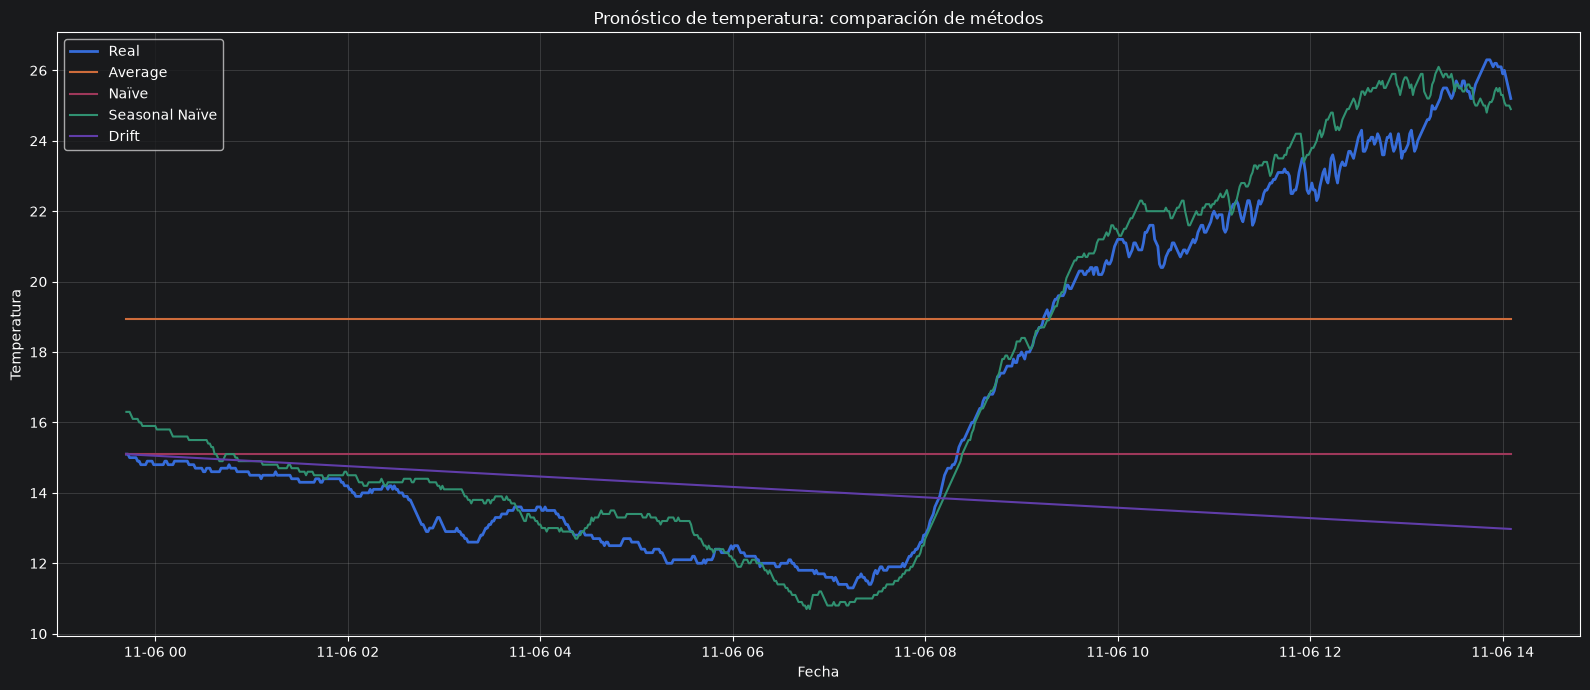

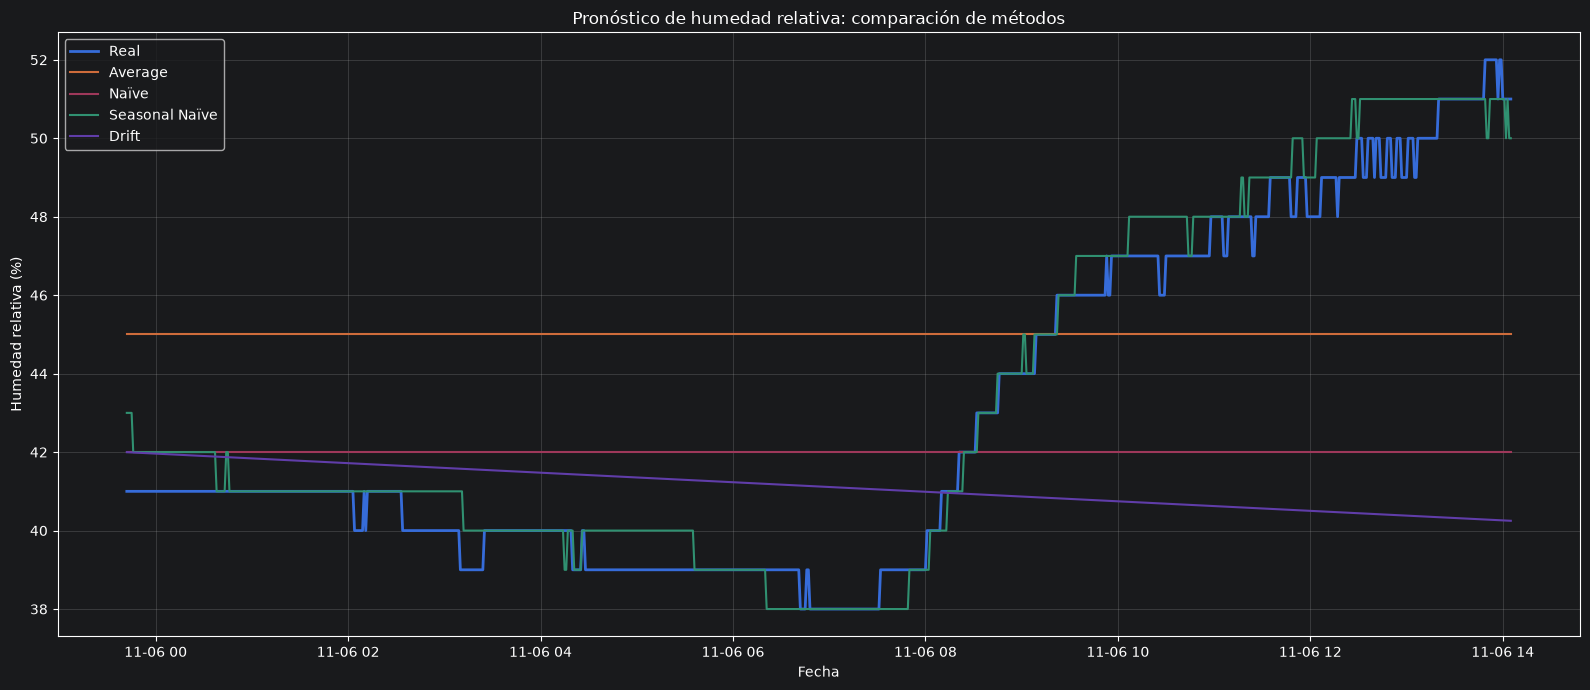

In [4]:
# ================================================================
# COMPARACIÓN DE MÉTODOS BÁSICOS DE PRONÓSTICO
#
# 1. Average
# 2. Naïve
# 3. Seasonal Naïve
# 4. Drift
#
# Variables:
#   tempAvg      -> Temperatura
#   humidityAvg  -> Humedad relativa
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ================================================================
# 1. PERIODO ESTACIONAL
# ================================================================
#
# Usamos el periodo diario calculado anteriormente.
# Si el intervalo es de 5 minutos:
#
#     m = 24 * 60 / 5 = 288
#
# m_diario ya fue calculado en el script anterior.
# ================================================================

m = m_diario

print("Periodo estacional utilizado:")
print(f"m = {m} observaciones")


# ================================================================
# 2. DIVISIÓN CRONOLÓGICA 80/20
# ================================================================

n = len(datos)

n_train = int(0.80 * n)

train = datos.iloc[:n_train].copy()
test  = datos.iloc[n_train:].copy()

print("\n==============================================")
print("DIVISIÓN DEL DATASET")
print("==============================================")

print(f"Total de observaciones : {n}")
print(f"Entrenamiento          : {len(train)}")
print(f"Prueba                 : {len(test)}")

print("\nPeriodo entrenamiento:")
print(train.index.min(), "->", train.index.max())

print("\nPeriodo prueba:")
print(test.index.min(), "->", test.index.max())


# ================================================================
# 3. MÉTODO AVERAGE
# ================================================================

def average_forecast(y_train, h):

    media = y_train.mean()

    return np.repeat(media, h)


# ================================================================
# 4. MÉTODO NAÏVE
# ================================================================

def naive_forecast(y_train, h):

    ultimo = y_train.iloc[-1]

    return np.repeat(ultimo, h)


# ================================================================
# 5. MÉTODO SEASONAL NAÏVE
# ================================================================

def seasonal_naive_forecast(y_train, h, m):

    if len(y_train) < m:
        raise ValueError(
            "No existen suficientes observaciones "
            "para completar un periodo estacional."
        )

    ultima_temporada = y_train.iloc[-m:].to_numpy()

    pronostico = np.resize(
        ultima_temporada,
        h
    )

    return pronostico


# ================================================================
# 6. MÉTODO DRIFT
# ================================================================

def drift_forecast(y_train, h):

    y1 = y_train.iloc[0]
    yT = y_train.iloc[-1]

    T = len(y_train)

    pendiente = (yT - y1) / (T - 1)

    pasos = np.arange(1, h + 1)

    pronostico = (
        yT +
        pasos * pendiente
    )

    return pronostico


# ================================================================
# 7. MÉTRICAS
# ================================================================

def metricas(real, pred):

    real = np.asarray(real)
    pred = np.asarray(pred)

    mae = mean_absolute_error(
        real,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            real,
            pred
        )
    )

    r2 = r2_score(
        real,
        pred
    )

    # -----------------------------------------------
    # MAPE
    # -----------------------------------------------

    mascara = real != 0

    if np.any(mascara):

        mape = (
            np.mean(
                np.abs(
                    (real[mascara] - pred[mascara])
                    / real[mascara]
                )
            )
            * 100
        )

    else:

        mape = np.nan

    return mae, rmse, mape, r2


# ================================================================
# 8. FUNCIÓN GENERAL DE EVALUACIÓN
# ================================================================

def evaluar_modelos(
    train,
    test,
    variable,
    m
):

    y_train = train[variable]
    y_test = test[variable]

    h = len(y_test)

    # -----------------------------------------------
    # Pronósticos
    # -----------------------------------------------

    pred_average = average_forecast(
        y_train,
        h
    )

    pred_naive = naive_forecast(
        y_train,
        h
    )

    pred_snaive = seasonal_naive_forecast(
        y_train,
        h,
        m
    )

    pred_drift = drift_forecast(
        y_train,
        h
    )

    # -----------------------------------------------
    # DataFrame de resultados
    # -----------------------------------------------

    predicciones = pd.DataFrame(
        {
            "Real": y_test.to_numpy(),

            "Average":
                pred_average,

            "Naive":
                pred_naive,

            "Seasonal_Naive":
                pred_snaive,

            "Drift":
                pred_drift
        },

        index=y_test.index
    )

    # -----------------------------------------------
    # Calcular métricas
    # -----------------------------------------------

    resultados = []

    modelos = [
        "Average",
        "Naive",
        "Seasonal_Naive",
        "Drift"
    ]

    for modelo in modelos:

        mae, rmse, mape, r2 = metricas(
            predicciones["Real"],
            predicciones[modelo]
        )

        resultados.append(
            {
                "Modelo": modelo,
                "MAE": mae,
                "RMSE": rmse,
                "MAPE (%)": mape,
                "R2": r2
            }
        )

    tabla = pd.DataFrame(resultados)

    return predicciones, tabla


# ================================================================
# 9. EVALUACIÓN DE TEMPERATURA
# ================================================================

pred_temp, met_temp = evaluar_modelos(
    train,
    test,
    "T",
    m
)

met_temp["Variable"] = "Temperatura"


print("\n==============================================")
print("TEMPERATURA")
print("==============================================")

display(
    met_temp[
        [
            "Modelo",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "R2"
        ]
    ].round(4)
)


# ================================================================
# 10. EVALUACIÓN DE HUMEDAD RELATIVA
# ================================================================

pred_hum, met_hum = evaluar_modelos(
    train,
    test,
    "H",
    m
)

met_hum["Variable"] = "Humedad relativa"


print("\n==============================================")
print("HUMEDAD RELATIVA")
print("==============================================")

display(
    met_hum[
        [
            "Modelo",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "R2"
        ]
    ].round(4)
)


# ================================================================
# 11. TABLA GENERAL
# ================================================================

comparacion = pd.concat(
    [
        met_temp,
        met_hum
    ],
    ignore_index=True
)

comparacion = comparacion[
    [
        "Variable",
        "Modelo",
        "MAE",
        "RMSE",
        "MAPE (%)",
        "R2"
    ]
]


print("\n==============================================")
print("COMPARACIÓN GENERAL")
print("==============================================")

display(
    comparacion.round(4)
)


# ================================================================
# 12. MEJOR MODELO SEGÚN RMSE
# ================================================================

print("\n==============================================")
print("MEJOR MODELO SEGÚN RMSE")
print("==============================================")

for variable in comparacion["Variable"].unique():

    aux = comparacion[
        comparacion["Variable"] == variable
    ]

    mejor = aux.loc[
        aux["RMSE"].idxmin()
    ]

    print(
        f"\n{variable}: "
        f"{mejor['Modelo']}"
    )

    print(
        f"RMSE = {mejor['RMSE']:.4f}"
    )

    print(
        f"MAE  = {mejor['MAE']:.4f}"
    )

    print(
        f"MAPE = {mejor['MAPE (%)']:.4f} %"
    )

    print(
        f"R²   = {mejor['R2']:.4f}"
    )


# ================================================================
# 13. GRÁFICA TEMPERATURA
# ================================================================
#
# Se muestran los primeros 7 días del conjunto de prueba.
# ================================================================

n_grafica = min(
    3 * m,
    len(pred_temp)
)

plt.figure(figsize=(16,7))

plt.plot(
    pred_temp.index[:n_grafica],
    pred_temp["Real"].iloc[:n_grafica],
    label="Real",
    linewidth=2
)

plt.plot(
    pred_temp.index[:n_grafica],
    pred_temp["Average"].iloc[:n_grafica],
    label="Average"
)

plt.plot(
    pred_temp.index[:n_grafica],
    pred_temp["Naive"].iloc[:n_grafica],
    label="Naïve"
)

plt.plot(
    pred_temp.index[:n_grafica],
    pred_temp["Seasonal_Naive"].iloc[:n_grafica],
    label="Seasonal Naïve"
)

plt.plot(
    pred_temp.index[:n_grafica],
    pred_temp["Drift"].iloc[:n_grafica],
    label="Drift"
)

plt.title(
    "Pronóstico de temperatura: comparación de métodos"
)

plt.xlabel("Fecha")
plt.ylabel("Temperatura")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ================================================================
# 14. GRÁFICA HUMEDAD RELATIVA
# ================================================================

n_grafica = min(
    7 * m,
    len(pred_hum)
)

plt.figure(figsize=(16,7))

plt.plot(
    pred_hum.index[:n_grafica],
    pred_hum["Real"].iloc[:n_grafica],
    label="Real",
    linewidth=2
)

plt.plot(
    pred_hum.index[:n_grafica],
    pred_hum["Average"].iloc[:n_grafica],
    label="Average"
)

plt.plot(
    pred_hum.index[:n_grafica],
    pred_hum["Naive"].iloc[:n_grafica],
    label="Naïve"
)

plt.plot(
    pred_hum.index[:n_grafica],
    pred_hum["Seasonal_Naive"].iloc[:n_grafica],
    label="Seasonal Naïve"
)

plt.plot(
    pred_hum.index[:n_grafica],
    pred_hum["Drift"].iloc[:n_grafica],
    label="Drift"
)

plt.title(
    "Pronóstico de humedad relativa: comparación de métodos"
)

plt.xlabel("Fecha")
plt.ylabel("Humedad relativa (%)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
# ================================================================
# ANÁLISIS DE RESIDUALES / ERRORES DE PRONÓSTICO
#
# e_t = y_t - y_hat_t
#
# Métodos:
#   1. Average
#   2. Naïve
#   3. Seasonal Naïve
#   4. Drift
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox


# ================================================================
# 1. FUNCIÓN PARA CALCULAR RESIDUALES
# ================================================================

def calcular_residuales(predicciones):

    residuales = pd.DataFrame(
        index=predicciones.index
    )

    modelos = [
        "Average",
        "Naive",
        "Seasonal_Naive",
        "Drift"
    ]

    for modelo in modelos:

        residuales[modelo] = (
            predicciones["Real"]
            - predicciones[modelo]
        )

    return residuales


# ================================================================
# 2. RESIDUALES DE TEMPERATURA
# ================================================================

res_temp = calcular_residuales(
    pred_temp
)

print("RESIDUALES - TEMPERATURA")

display(
    res_temp.head(10)
)


# ================================================================
# 3. RESIDUALES DE HUMEDAD RELATIVA
# ================================================================

res_hum = calcular_residuales(
    pred_hum
)

print("RESIDUALES - HUMEDAD RELATIVA")

display(
    res_hum.head(10)
)

RESIDUALES - TEMPERATURA


,Average,Naive,Seasonal_Naive,Drift
datetime,,,,
2026-11-05 23:42:00,-3.832697,0.0,-1.2,0.002460
2026-11-05 23:43:00,-3.832697,0.0,-1.2,0.004920
2026-11-05 23:44:00,-3.932697,-0.1,-1.3,-0.092619
2026-11-05 23:45:00,-3.932697,-0.1,-1.2,-0.090159
2026-11-05 23:46:00,-3.932697,-0.1,-1.1,-0.087699
2026-11-05 23:47:00,-3.932697,-0.1,-1.1,-0.085239
2026-11-05 23:48:00,-3.932697,-0.1,-1.1,-0.082779
2026-11-05 23:49:00,-4.032697,-0.2,-1.2,-0.180318
2026-11-05 23:50:00,-4.032697,-0.2,-1.1,-0.177858


RESIDUALES - HUMEDAD RELATIVA


,Average,Naive,Seasonal_Naive,Drift
datetime,,,,
2026-11-05 23:42:00,-4.011863,-1,-2,-0.997974
2026-11-05 23:43:00,-4.011863,-1,-2,-0.995948
2026-11-05 23:44:00,-4.011863,-1,-2,-0.993922
2026-11-05 23:45:00,-4.011863,-1,-2,-0.991896
2026-11-05 23:46:00,-4.011863,-1,-1,-0.989870
2026-11-05 23:47:00,-4.011863,-1,-1,-0.987844
2026-11-05 23:48:00,-4.011863,-1,-1,-0.985818
2026-11-05 23:49:00,-4.011863,-1,-1,-0.983792
2026-11-05 23:50:00,-4.011863,-1,-1,-0.981766


In [6]:
# ================================================================
# 4. ESTADÍSTICA DESCRIPTIVA DE LOS RESIDUALES
# ================================================================

def resumen_residuales(residuales):

    resumen = pd.DataFrame({

        "Media":
            residuales.mean(),

        "Desv. estándar":
            residuales.std(),

        "Mínimo":
            residuales.min(),

        "Máximo":
            residuales.max(),

        "Mediana":
            residuales.median(),

        "RMSE":
            np.sqrt(
                (residuales**2).mean()
            )

    })

    return resumen


# ------------------------------------------------
# Temperatura
# ------------------------------------------------

resumen_temp = resumen_residuales(
    res_temp
)

print("\n======================================")
print("RESUMEN RESIDUALES - TEMPERATURA")
print("======================================")

display(
    resumen_temp.round(4)
)


# ------------------------------------------------
# Humedad
# ------------------------------------------------

resumen_hum = resumen_residuales(
    res_hum
)

print("\n======================================")
print("RESUMEN RESIDUALES - HUMEDAD")
print("======================================")

display(
    resumen_hum.round(4)
)


RESUMEN RESIDUALES - TEMPERATURA


,Media,Desv. estándar,Mínimo,Máximo,Mediana,RMSE
Average,-2.2873,4.6138,-7.6327,7.3673,-4.4327,5.1473
Naive,1.5454,4.6138,-3.8000,11.2000,-0.6000,4.8632
Seasonal_Naive,-0.4013,0.6806,-2.2000,1.5000,-0.4000,0.7898
Drift,2.6094,5.1134,-2.6904,13.2936,-0.3503,5.7381



RESUMEN RESIDUALES - HUMEDAD


,Media,Desv. estándar,Mínimo,Máximo,Mediana,RMSE
Average,-2.0929,4.2079,-7.0119,6.9881,-4.0119,4.6974
Naive,0.9190,4.2079,-4.0000,10.0000,-1.0000,4.3047
Seasonal_Naive,-0.3866,0.7017,-2.0000,2.0000,0.0000,0.8008
Drift,1.7952,4.6190,-3.1470,11.7384,-0.8187,4.9531


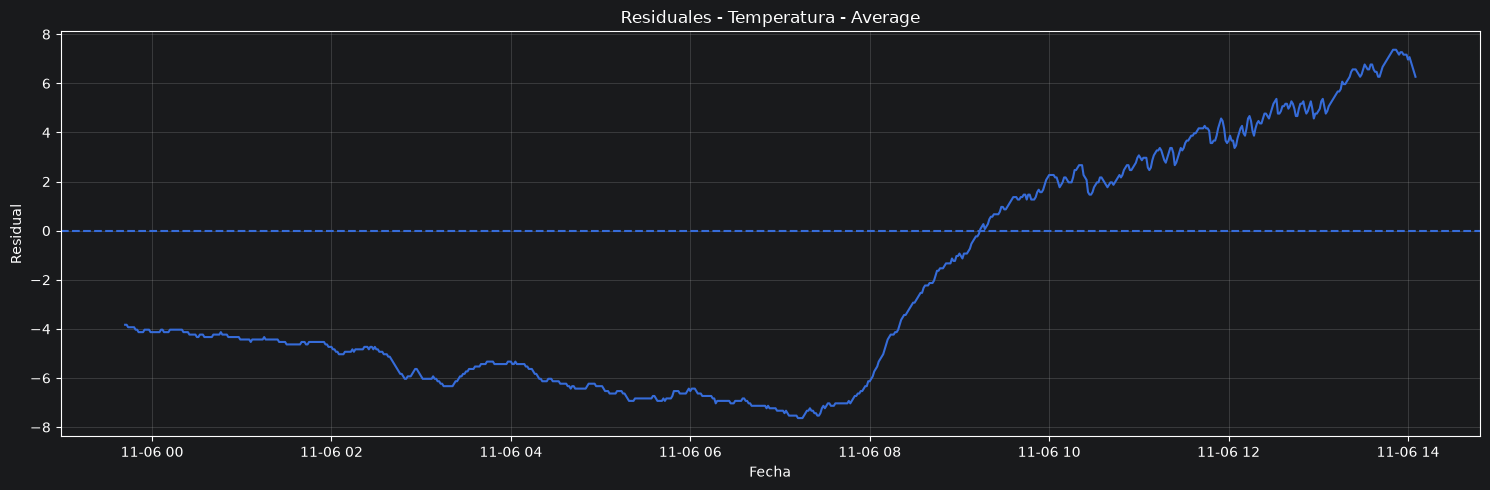

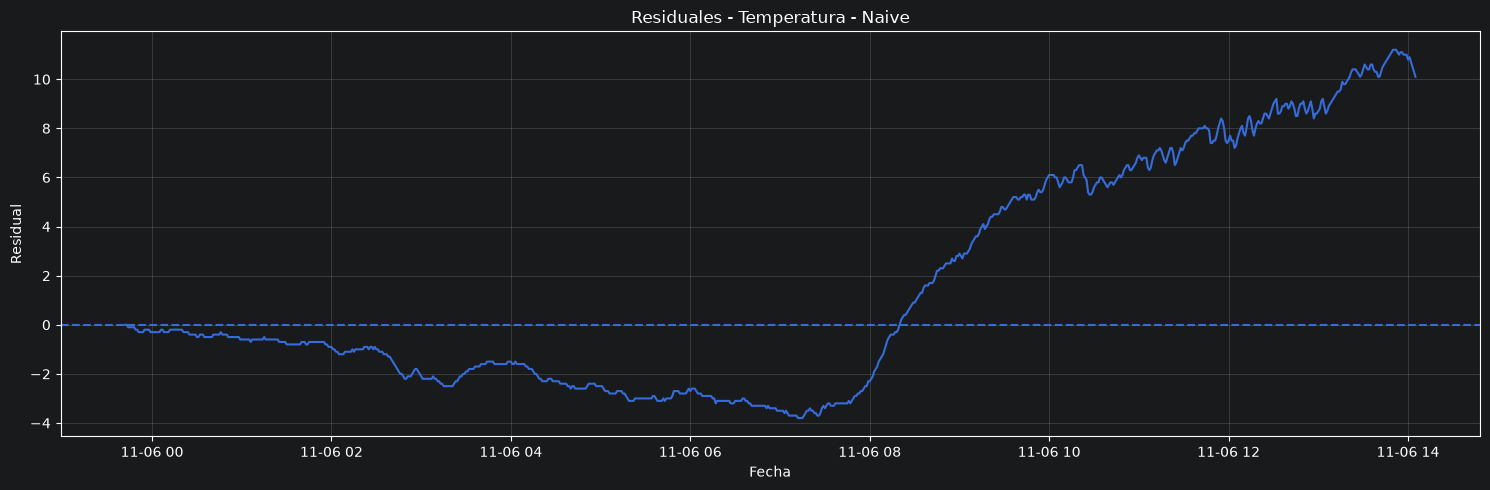

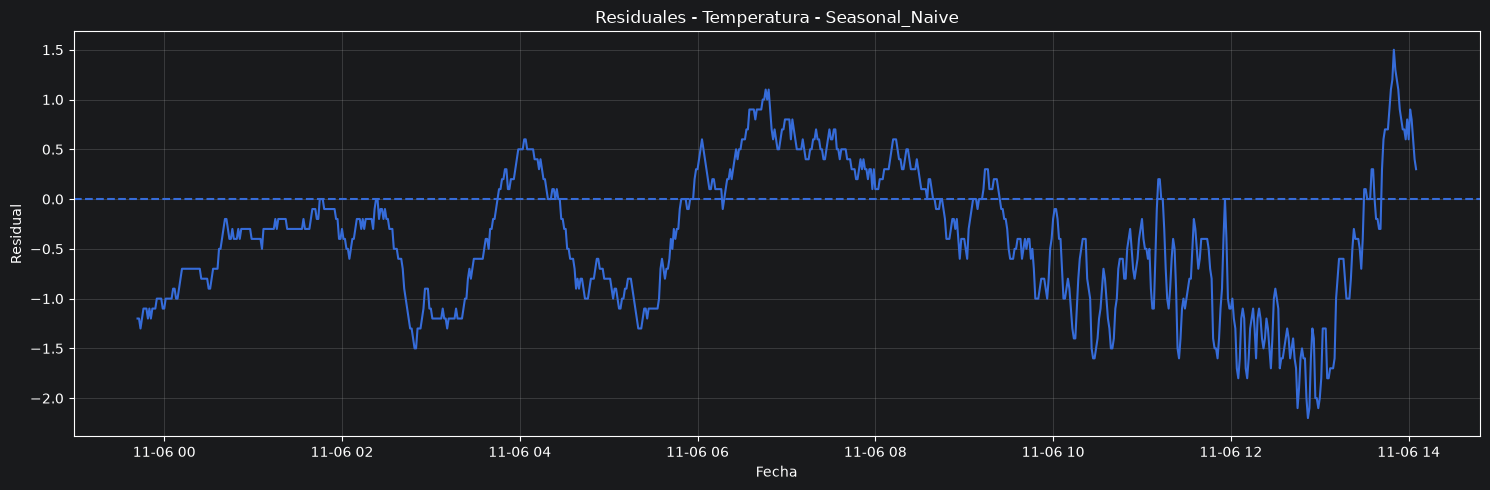

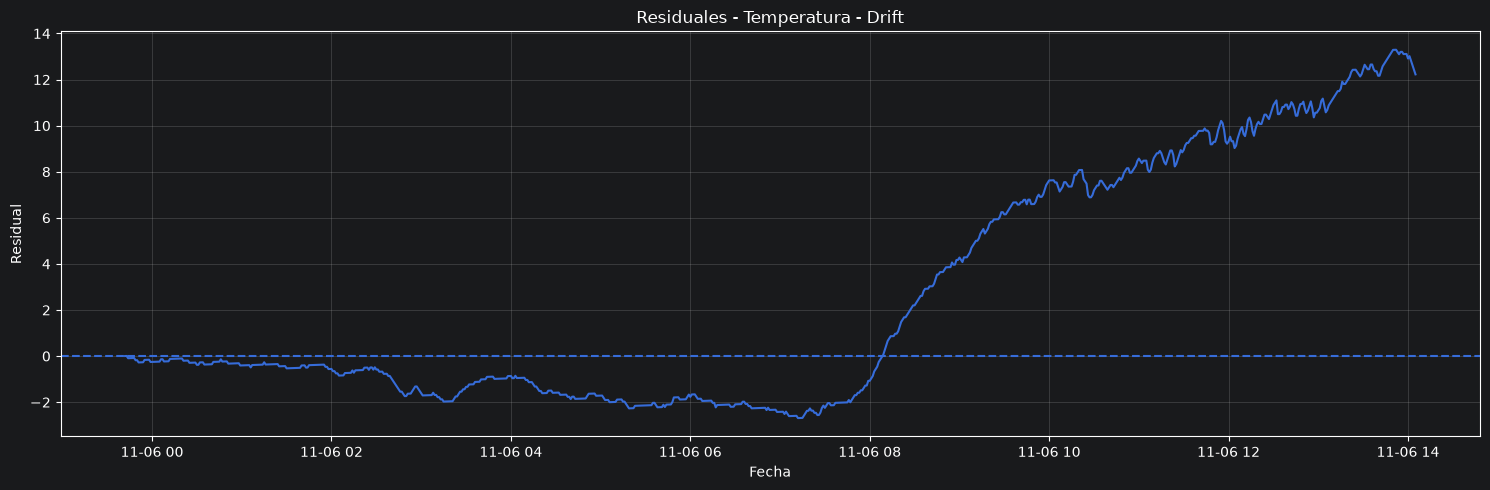

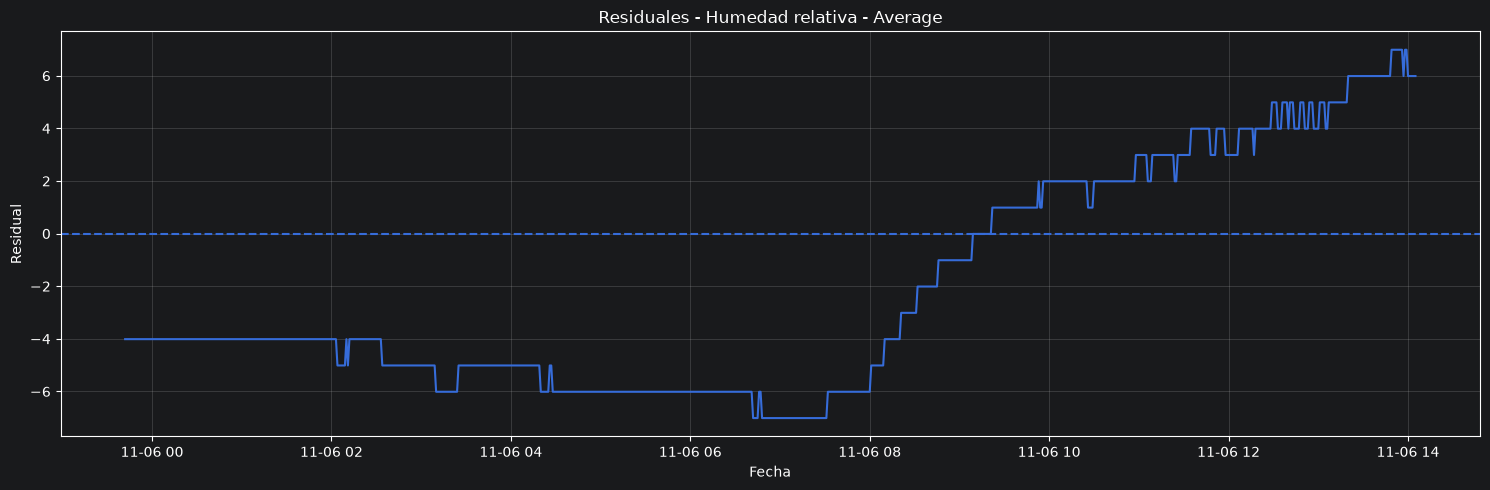

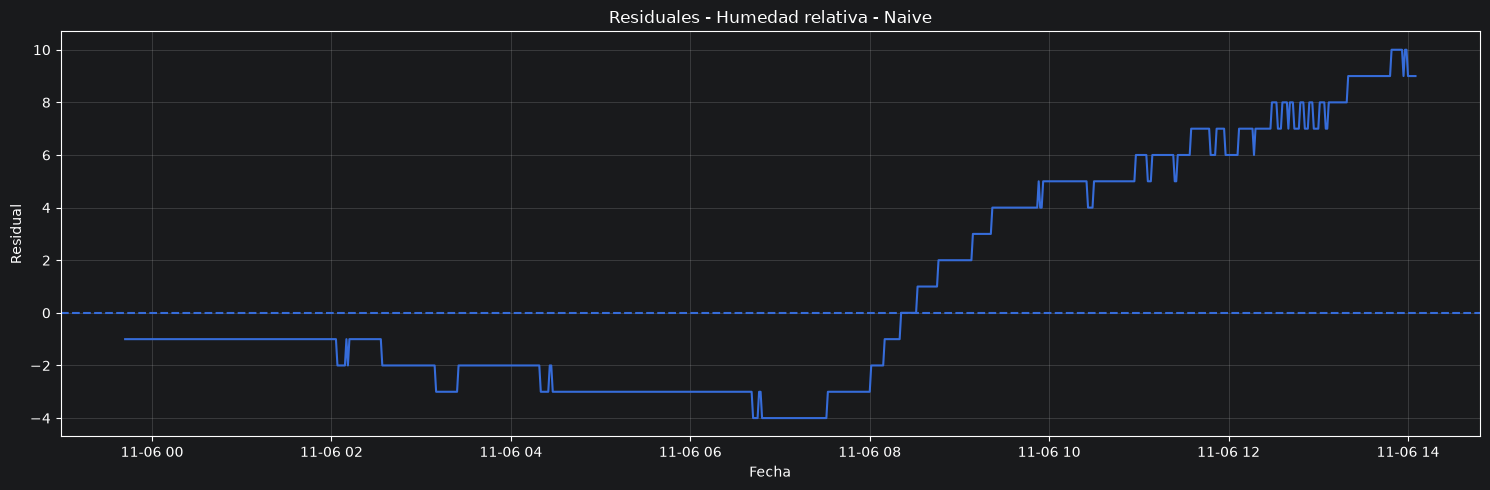

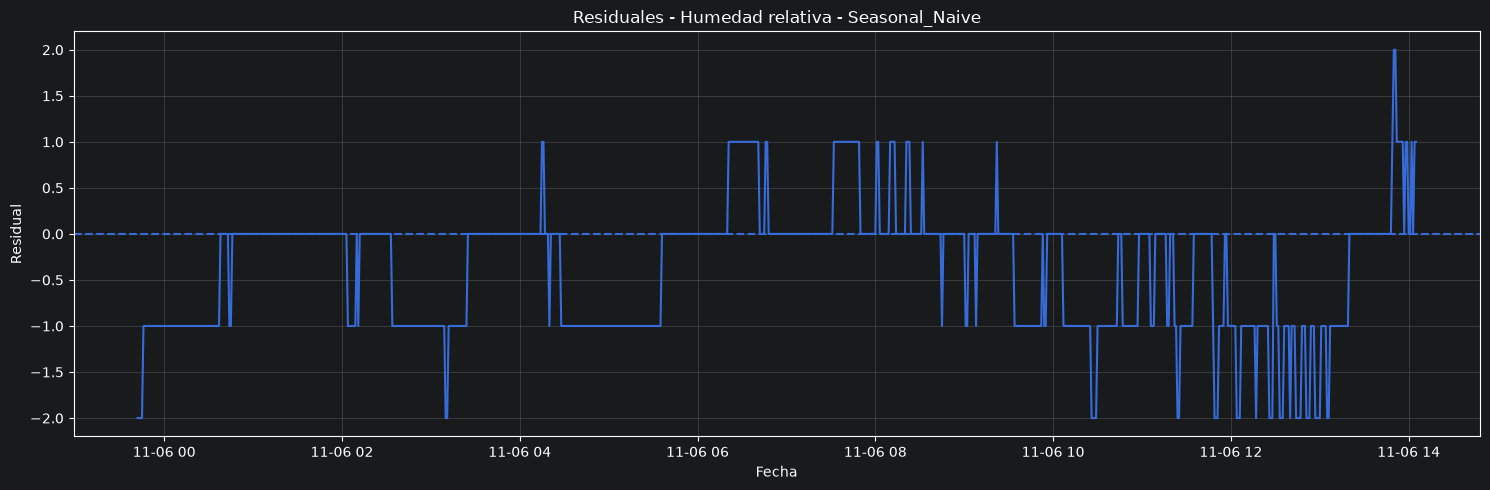

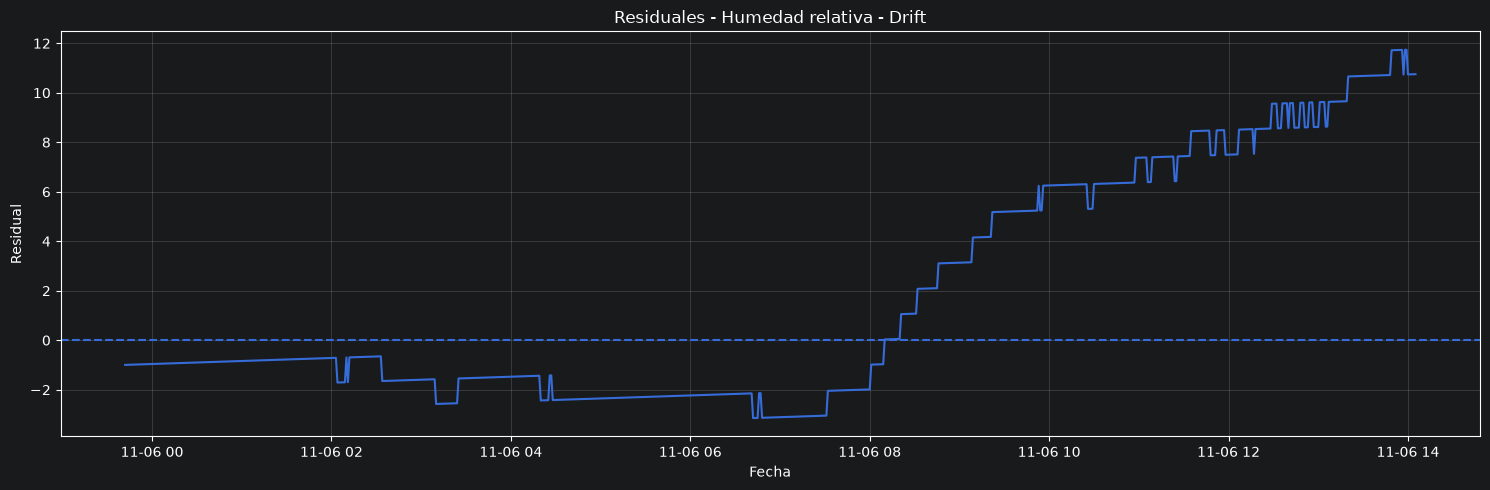

In [7]:
# ================================================================
# 5. GRÁFICAS DE RESIDUALES
# ================================================================

def graficar_residuales(
    residuales,
    variable,
    n=2000
):

    modelos = residuales.columns

    n = min(
        n,
        len(residuales)
    )

    for modelo in modelos:

        plt.figure(
            figsize=(15, 5)
        )

        plt.plot(
            residuales.index[:n],
            residuales[modelo].iloc[:n]
        )

        plt.axhline(
            y=0,
            linestyle="--"
        )

        plt.title(
            f"Residuales - {variable} - {modelo}"
        )

        plt.xlabel("Fecha")
        plt.ylabel("Residual")

        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()


# Temperatura

graficar_residuales(
    res_temp,
    "Temperatura"
)


# Humedad relativa

graficar_residuales(
    res_hum,
    "Humedad relativa"
)

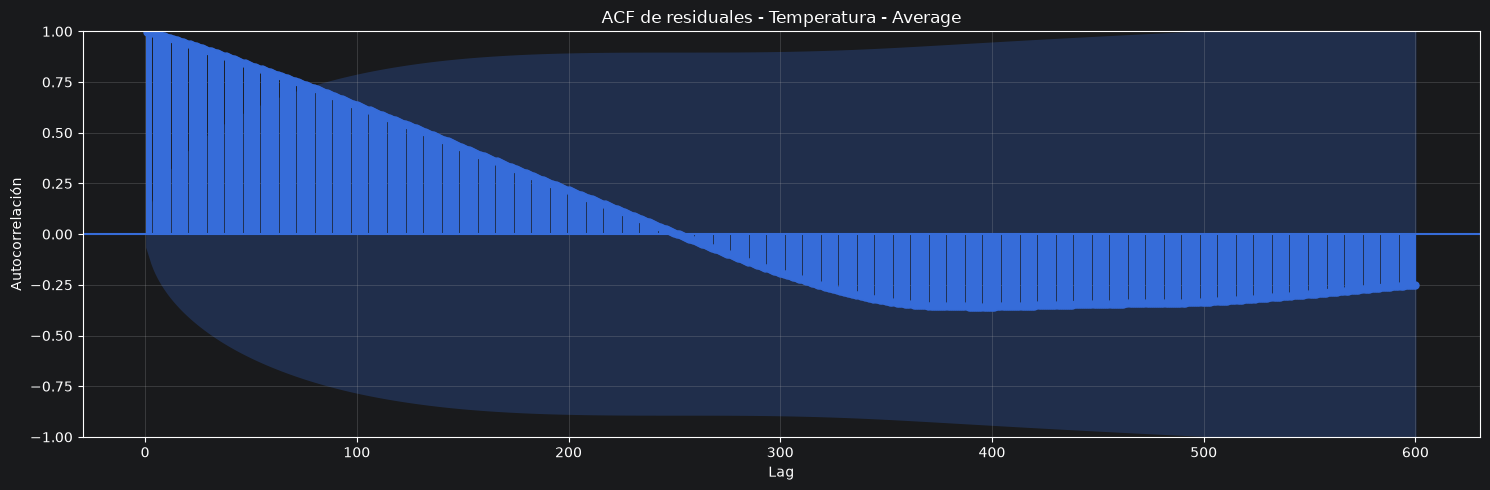

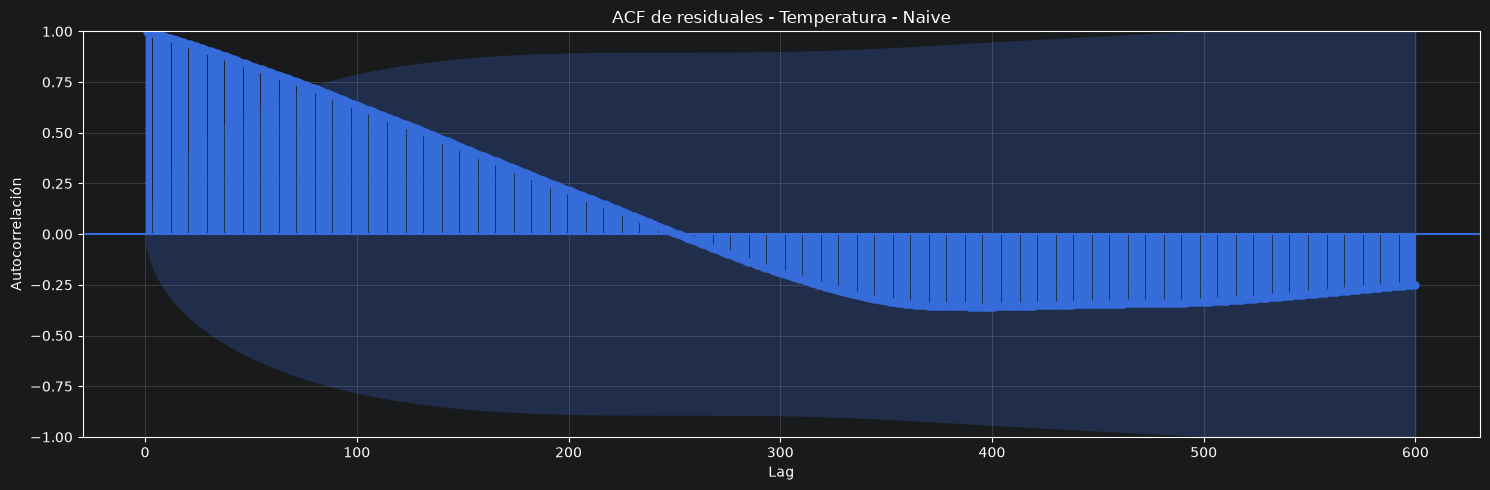

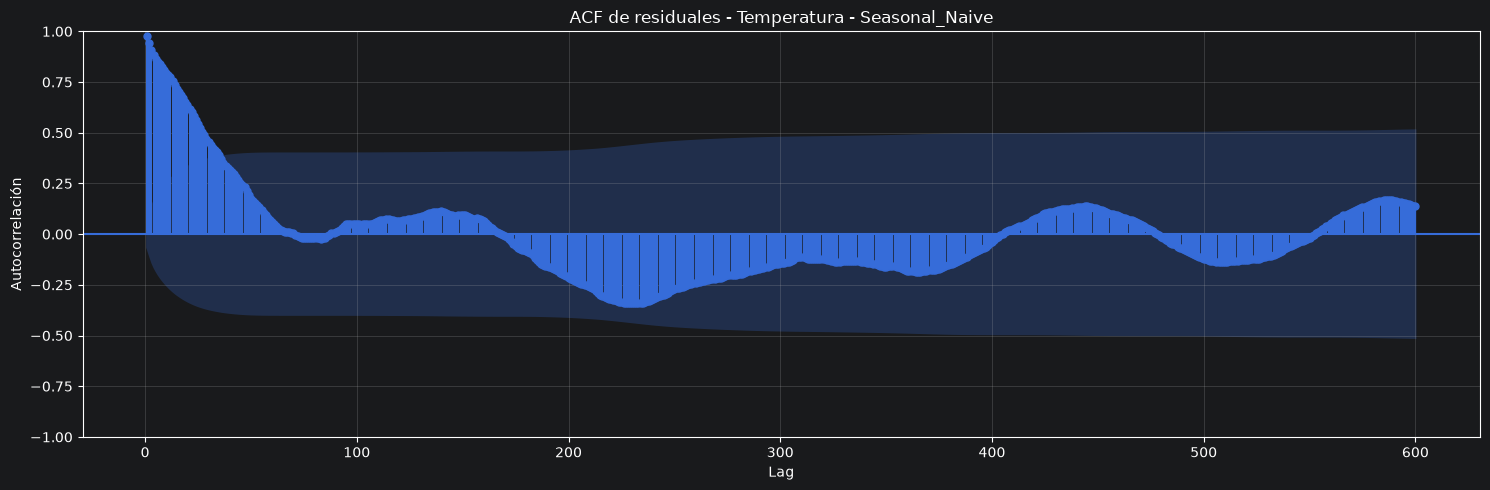

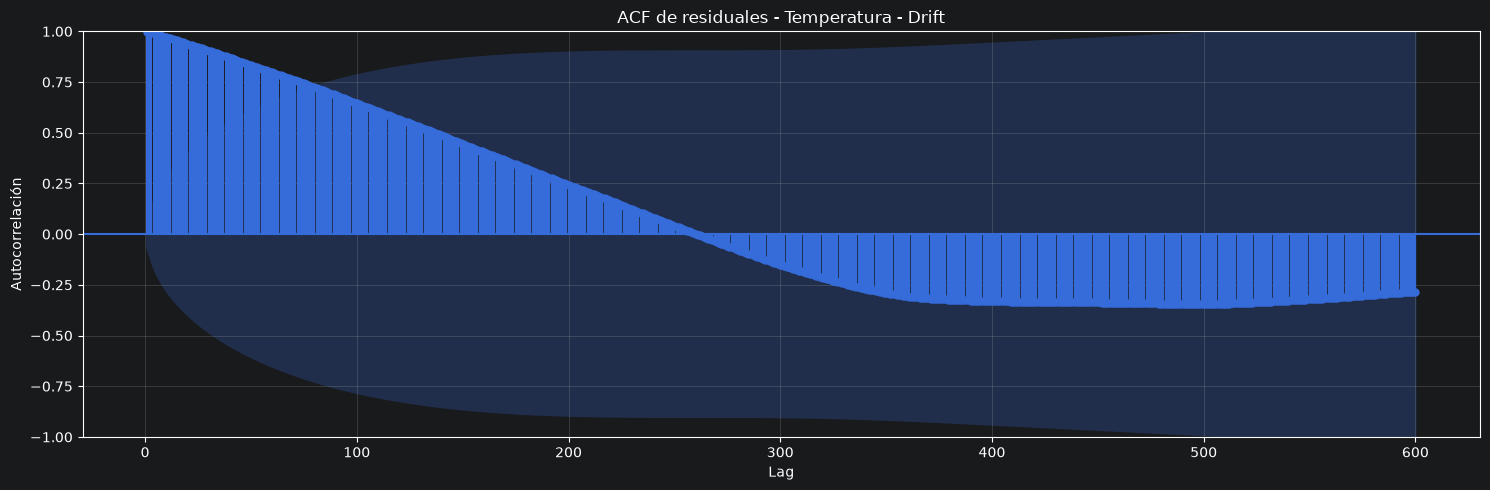

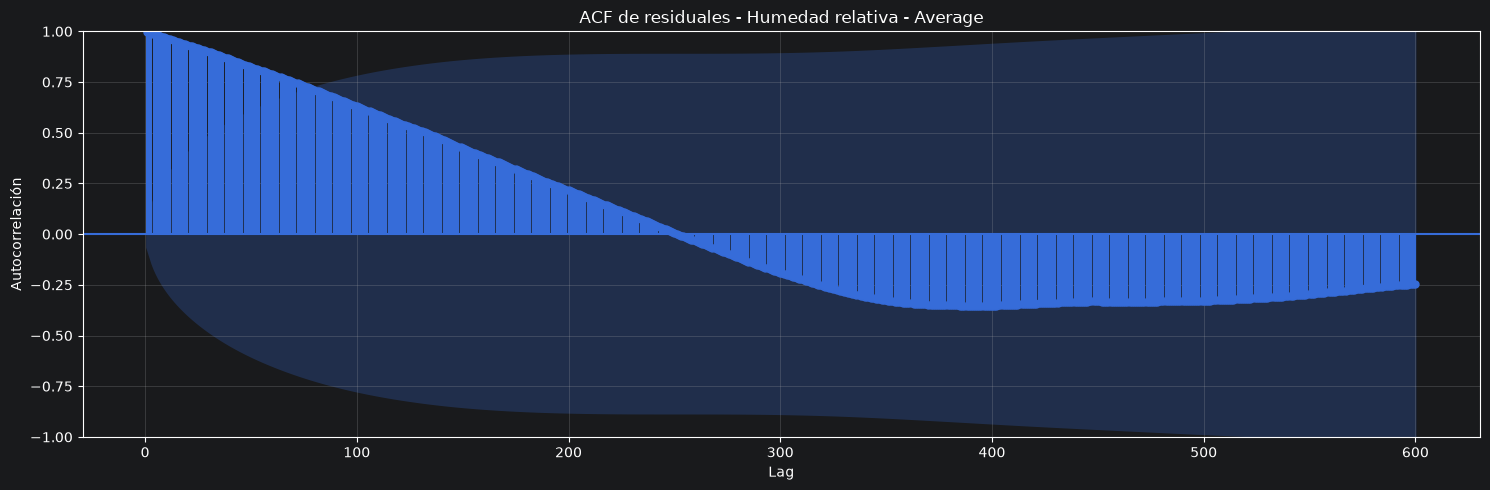

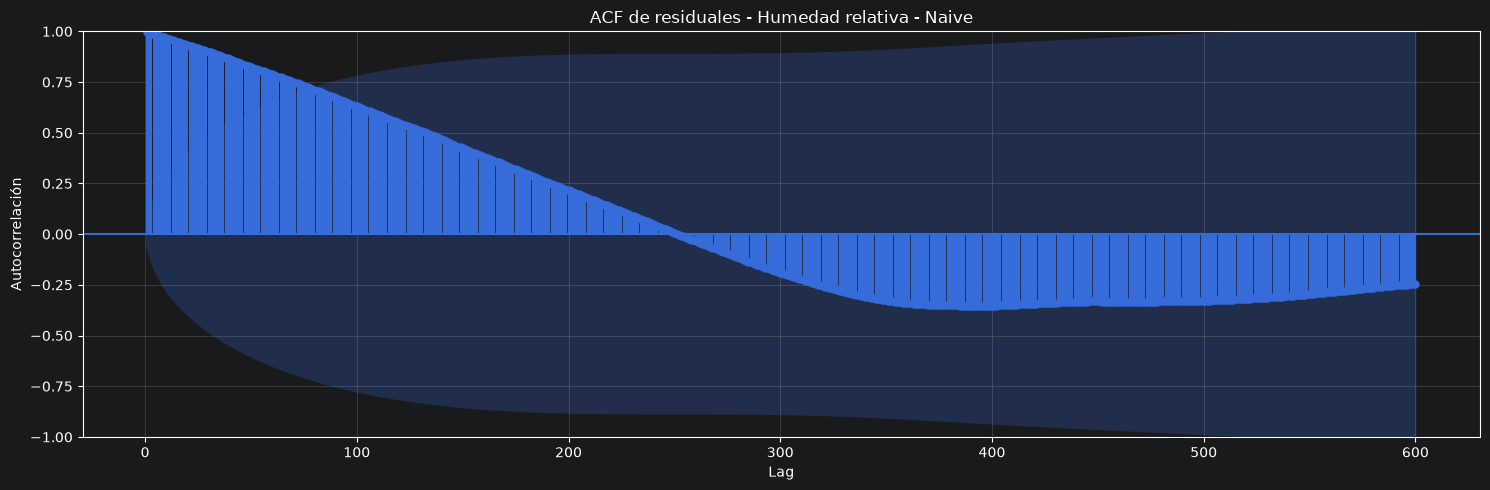

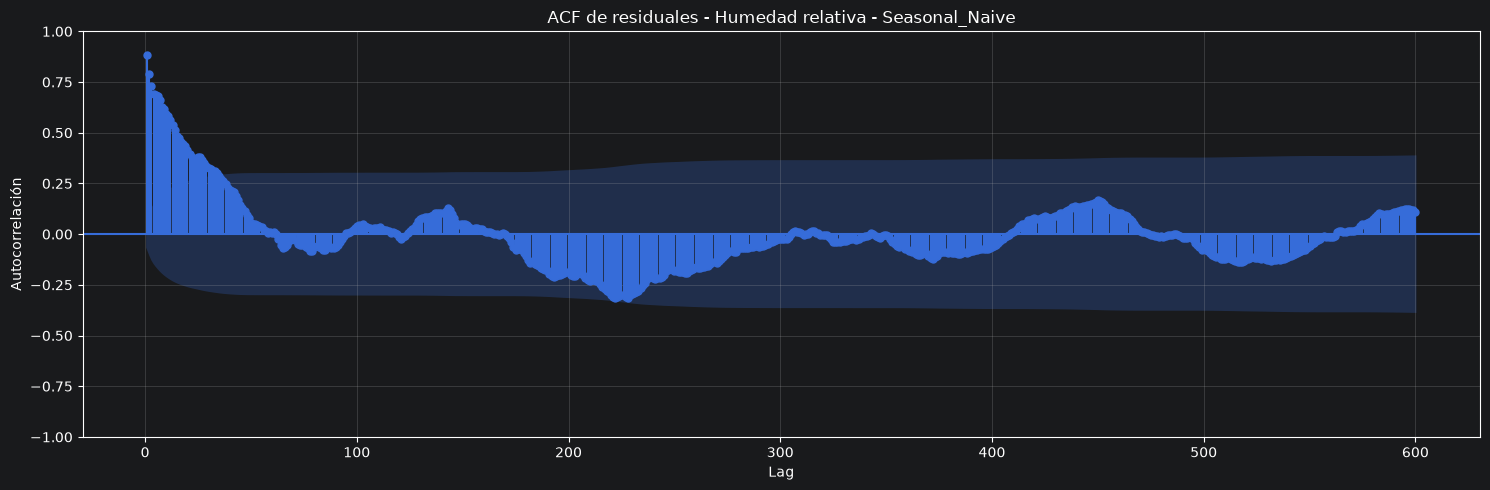

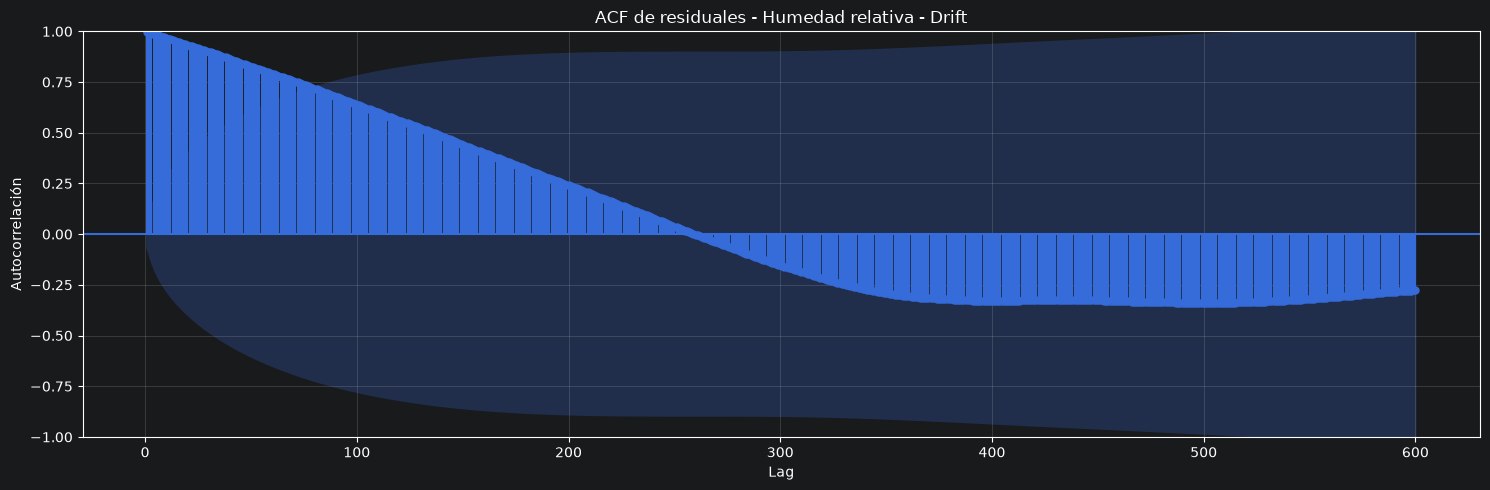

In [8]:
# ================================================================
# 6. ACF DE LOS RESIDUALES
# ================================================================

def acf_residuales(
    residuales,
    variable,
    lags=600
):

    for modelo in residuales.columns:

        fig, ax = plt.subplots(
            figsize=(15, 5)
        )

        plot_acf(
            residuales[modelo].dropna(),
            lags=lags,
            zero=False,
            ax=ax
        )

        ax.set_title(
            f"ACF de residuales - {variable} - {modelo}"
        )

        ax.set_xlabel("Lag")
        ax.set_ylabel("Autocorrelación")

        ax.grid(alpha=0.3)

        plt.tight_layout()
        plt.show()


# Temperatura

acf_residuales(
    res_temp,
    "Temperatura",
    lags=600
)


# Humedad relativa

acf_residuales(
    res_hum,
    "Humedad relativa",
    lags=600
)

In [9]:
# ================================================================
# 7. PRUEBA DE LJUNG-BOX
# ================================================================

def prueba_ljung_box(
    residuales,
    variable
):

    resultados = []

    # Lags representativos
    lags_evaluar = [
        12,
        72,
        144,
        288
    ]

    for modelo in residuales.columns:

        serie = (
            residuales[modelo]
            .dropna()
        )

        prueba = acorr_ljungbox(
            serie,
            lags=lags_evaluar,
            return_df=True
        )

        for lag in lags_evaluar:

            resultados.append({

                "Variable":
                    variable,

                "Modelo":
                    modelo,

                "Lag":
                    lag,

                "Q Ljung-Box":
                    prueba.loc[
                        lag,
                        "lb_stat"
                    ],

                "p-value":
                    prueba.loc[
                        lag,
                        "lb_pvalue"
                    ]

            })

    return pd.DataFrame(
        resultados
    )


# ------------------------------------------------
# Temperatura
# ------------------------------------------------

lb_temp = prueba_ljung_box(
    res_temp,
    "Temperatura"
)


# ------------------------------------------------
# Humedad
# ------------------------------------------------

lb_hum = prueba_ljung_box(
    res_hum,
    "Humedad relativa"
)


# ------------------------------------------------
# Tabla general
# ------------------------------------------------

ljung_box = pd.concat(
    [
        lb_temp,
        lb_hum
    ],
    ignore_index=True
)

display(
    ljung_box.round(6)
)

,Variable,Modelo,Lag,Q Ljung-Box,p-value
0,Temperatura,Average,12,10099.874210,0.0
1,Temperatura,Average,72,50431.386137,0.0
2,Temperatura,Average,144,76460.616343,0.0
3,Temperatura,Average,288,84575.311144,0.0
4,Temperatura,Naive,12,10099.874210,0.0
5,Temperatura,Naive,72,50431.386137,0.0
6,Temperatura,Naive,144,76460.616343,0.0
7,Temperatura,Naive,288,84575.311144,0.0
8,Temperatura,Seasonal_Naive,12,7668.360897,0.0
9,Temperatura,Seasonal_Naive,72,15647.899869,0.0
